In [314]:
import pandas as pd
filepath = 'data/result.csv'
df = pd.read_csv(filepath)
df.columns = df.columns.str.replace('_output.csv', '')
df.columns = df.columns.str.replace('output', '')
output_file_path = 'data/audioData3.csv'
df.to_csv(output_file_path, index=False)


In [374]:
import pandas as pd
filepath = 'data/audioData.csv'
audioData = pd.read_csv(filepath)

# columns_with_all_zeros = audioData.columns[audioData.eq(0).all()]

# # Print the column names with all zeros
# for col_name in columns_with_all_zeros:
#     print(f"Column '{col_name}' has all values equal to 0.")


pitchAverages = audioData[audioData != 0].mean(axis=0)
pitchAverages = pitchAverages.reset_index(drop=False)
pitchAverages.columns = ['Clip_ID', 'pitchAverage']

# DROP 0 VALUES 
# pitchAverages = pitchAverages.drop([205,558])
pitchAverages = pitchAverages[pitchAverages['Clip_ID'] != 'cut_feb2203-human-20']
pitchAverages = pitchAverages[pitchAverages['Clip_ID'] != 'cut_feb2803-human-13']
print("Column Averages (excluding 0s):")
print(pitchAverages)


# pitchMax = audioData[audioData != 0].max(axis=0)
# pitchMax = pitchMax.reset_index(drop=False)
# pitchMax.columns = ['Clip_ID', 'pitchMaximum']
# # pitchMax = pitchMax.drop([205,558])
# pitchMax = pitchMax[pitchMax['Clip_ID'] != 'cut_feb2203-human-20']
# pitchMax = pitchMax[pitchMax['Clip_ID'] != 'cut_feb2803-human-13']
# print("Column Max (excluding 0s):")
# # print(pitchMax)



Column Averages (excluding 0s):
                    Clip_ID  pitchAverage
0    cut_feb0905-guest-4-20    135.998745
1      cut_feb2505-human-12    143.196002
2      cut_feb2402-human-13    225.121204
3      cut_feb1804-human-11    154.856671
4      cut_feb2302-human-10    101.621564
..                      ...           ...
635   cut_feb1603-guest-0-2    110.826311
636    cut_feb0305-human-19    196.399900
637   cut_feb1405-guest-1-6    144.533166
638     cut_feb1502-human-8     93.272844
639    cut_feb0202-human-18    230.342077

[638 rows x 2 columns]


## Distribution of the mean pitch per audio clip

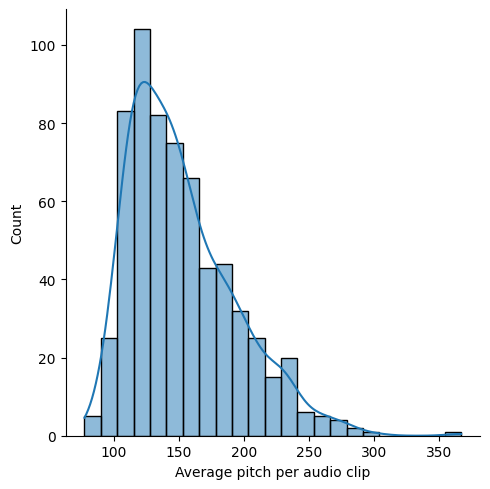

In [394]:
display(Markdown('## Distribution of the mean pitch per audio clip'))
plot = sns.displot(pitchAverages['pitchAverage'], kde=True)
plot.set_axis_labels('Average pitch per audio clip', "Count")

In [355]:
%run ./dataManipulationFunctions.ipynb

In [376]:
from scipy.stats import spearmanr

bigFive = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']

data = pd.DataFrame(medianScoresPerClip(), columns=['Clip_ID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness'])

# pitchWithFeaturesMax = pd.merge(pitchMax, data, on='Clip_ID')
pitchWithFeaturesAv = pd.merge(pitchAverages, data, on='Clip_ID')


In [377]:
# T TEST to see the difference between the pitch for female and male

# tStatistic, pValue = scipy.stats.ttest_ind(a=femaleOnlyMax['pitchMaximum'], b=maleOnlyMax['pitchMaximum'], equal_var=True)
# result = [tStatistic, pValue]
# print(result)

tStatistic, pValue = scipy.stats.ttest_ind(a=femaleOnlyAv['pitchAverage'], b=maleOnlyAv['pitchAverage'], equal_var=True)
result = [tStatistic, pValue]
print(result)

[7.091917143715987, 3.5332355718679572e-12]


In [385]:
metadata = pd.read_csv('data/metadata.csv')

sexId = metadata.loc[:,['Clip_ID', 'Gender']].copy()
mergedDfAv = pd.merge(pitchWithFeaturesAv, sexId, on='Clip_ID')

femaleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'F']
maleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'M']




In [380]:
# MEAN PITCH PER CATEGORY

x = femaleOnlyAv['pitchAverage'].mean()
print('Mean female pitch', x)

x = maleOnlyAv['pitchAverage'].mean()
print('Mean male pitch', x)

Mean female pitch 173.45030950589475
Mean male pitch 146.46699187742104


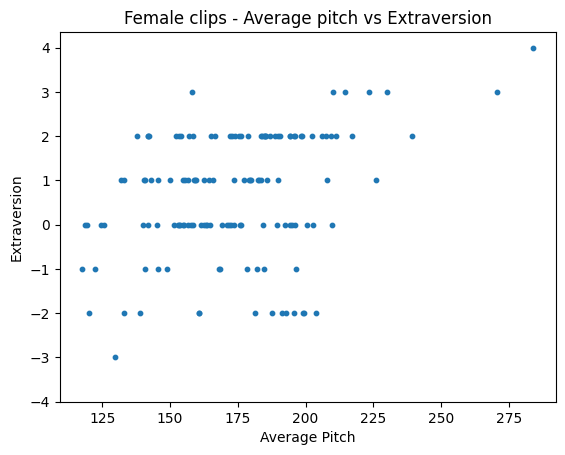

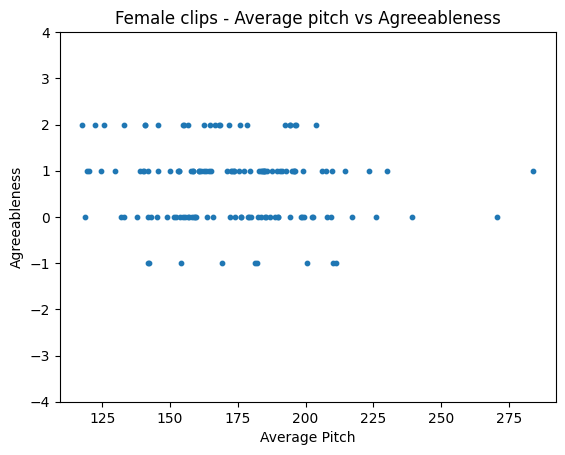

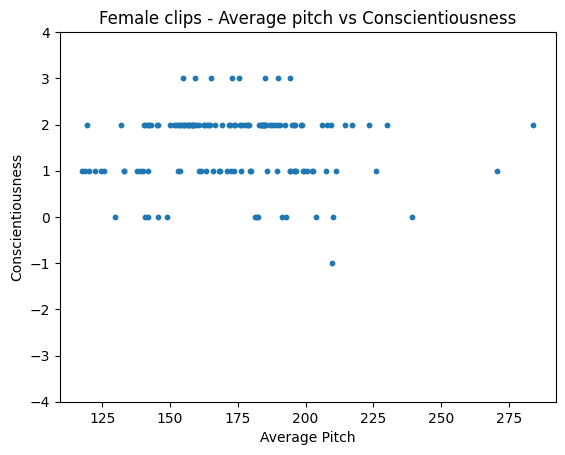

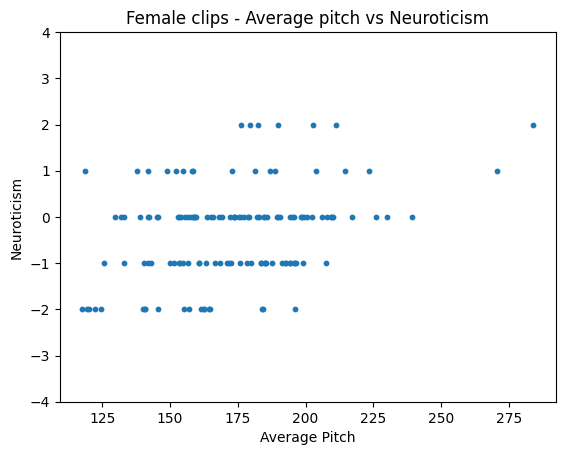

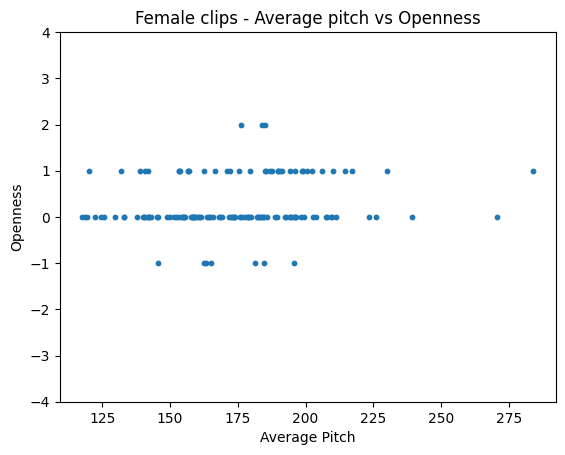

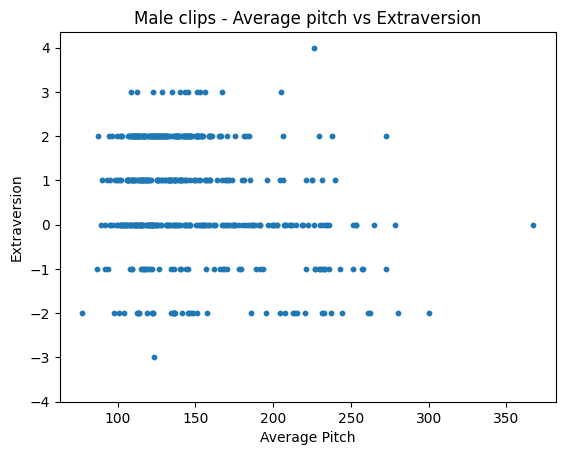

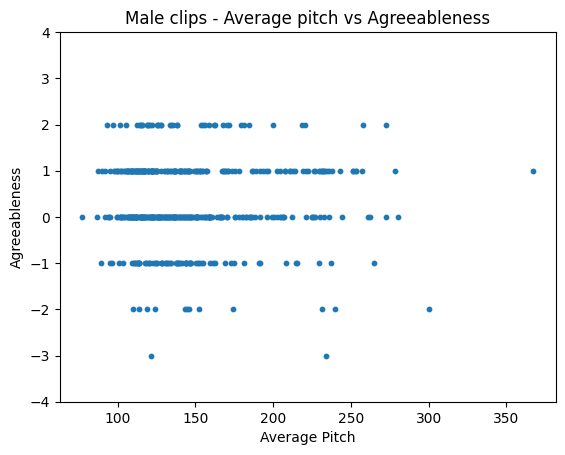

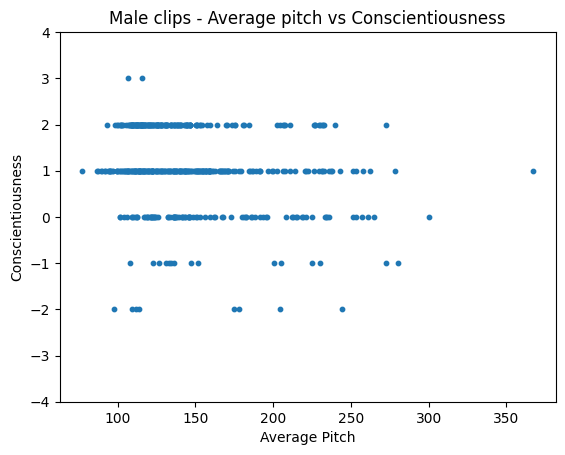

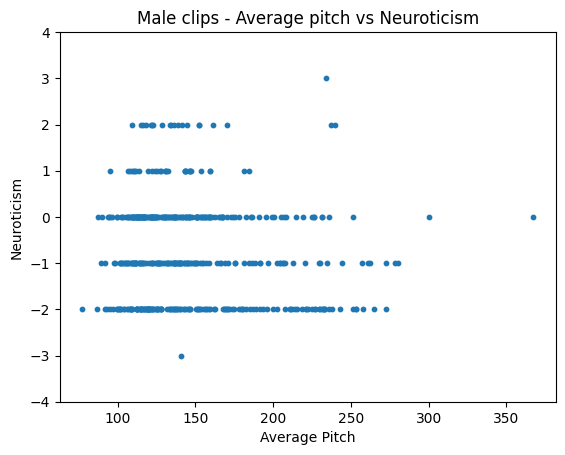

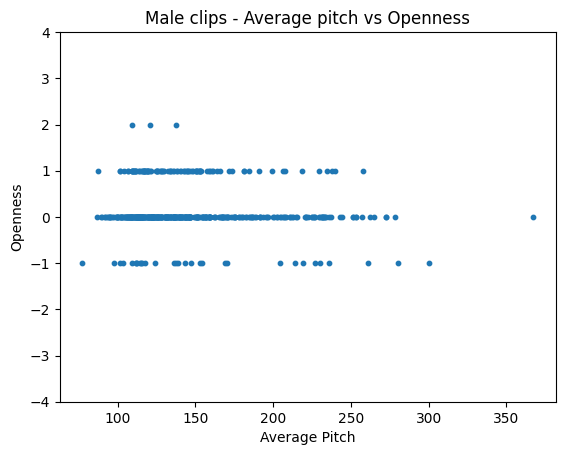

In [381]:

for trait in bigFive:    
    plt.scatter(femaleOnlyAv['pitchAverage'], femaleOnlyAv[trait], s=10)
    plt.xlabel('Average Pitch')
    plt.ylabel(trait)
    plt.title(f'Female clips - Average pitch vs {trait}')
    plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
    plt.show()

for trait in bigFive:    
    plt.scatter(maleOnlyAv['pitchAverage'], maleOnlyAv[trait], s=10)
    plt.xlabel('Average Pitch')
    plt.ylabel(trait)
    plt.title(f'Male clips - Average pitch vs {trait}')
    plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
    plt.show()


In [383]:

display(Markdown('## Average Pitch'))
for trait in bigFive:
    rho, p = spearmanr(pitchWithFeaturesAv['pitchAverage'],pitchWithFeaturesAv[trait])
    print(trait,': ','rho = ',rho, ' p =',p)


display(Markdown('## Female Average Pitch'))
for trait in bigFive:
    rho, p = spearmanr(femaleOnlyAv['pitchAverage'],femaleOnlyAv[trait])
    print(trait,': ','rho = ',rho, ' p =',p)

display(Markdown('## Male Average Pitch'))
for trait in bigFive:
    rho, p = spearmanr(maleOnlyAv['pitchAverage'],maleOnlyAv[trait])
    print(trait,': ','rho = ',rho, ' p =',p)
 



## Average Pitch

Extraversion :  rho =  -0.10666293681159374  p = 0.007005638846793193
Agreeableness :  rho =  0.05483303936158736  p = 0.16656246827574586
Conscientiousness :  rho =  -0.08260441799446344  p = 0.03698302645686165
Neuroticism :  rho =  0.019906579733875877  p = 0.6157538526982627
Openness :  rho =  0.007692138508147405  p = 0.8462424519603488


## Female Average Pitch

Extraversion :  rho =  0.29996085263699185  p = 0.00036923728413690803
Agreeableness :  rho =  -0.10846635536205104  p = 0.20707134294469745
Conscientiousness :  rho =  -0.008762414675792836  p = 0.9190554072079797
Neuroticism :  rho =  0.2700543581020786  p = 0.0014155775339659519
Openness :  rho =  0.15968891323594708  p = 0.062326646520722256


## Male Average Pitch

Extraversion :  rho =  -0.16611627317000371  p = 0.0001878059897487038
Agreeableness :  rho =  -0.004459608994491094  p = 0.9206851429834746
Conscientiousness :  rho =  -0.2173345087267958  p = 9.048454498964794e-07
Neuroticism :  rho =  -0.07182899987971927  p = 0.10831580164408453
Openness :  rho =  -0.04062634795952741  p = 0.3641720558767184


In [388]:
# SPLIT PER GENDER

print('Female from mean pitch in recording -->    min: ', femaleOnlyAv['pitchAverage'].min(), 'max: ', femaleOnlyAv['pitchAverage'].max())
print('Male from mean pitch in recording -->    min: ', maleOnlyAv['pitchAverage'].min(), 'max: ', maleOnlyAv['pitchAverage'].max())

Female from mean pitch in recording -->    min:  117.65698237179487 max:  283.99648791916167
Male from mean pitch in recording -->    min:  77.28683352941177 max:  367.32023
